# Chuyển giá trị số thành các giá trị phân loại

# Chuyển giá trị số thành giá trị phân loại bằng `bins` và `pd.cut()`

Đoạn code:

```python
bins = np.linspace(min(df["price"]), max(df["price"]), 4)

group_names = ['Thấp', 'Vừa', 'Cao']

df['price-bin'] = pd.cut(
    df['price'],
    bins,
    labels=group_names,
    include_lowest=True
)
```

## 1. Mục đích

Đoạn code dùng để **chia các giá trị số của cột `price` thành các nhóm**.

Ví dụ:

* Giá thấp → **Thấp**
* Giá trung bình → **Vừa**
* Giá cao → **Cao**

Tức là biến `price` từ dạng **số** được chuyển thành dạng **phân loại (categorical)**.

---

## 2. Dòng 1: Tạo `bins`

```python
bins = np.linspace(min(df["price"]), max(df["price"]), 4)
```

### `min(df["price"])`

→ Tìm **giá nhỏ nhất** trong cột `price`.

### `max(df["price"])`

→ Tìm **giá lớn nhất** trong cột `price`.

### `np.linspace(..., 4)`

→ Tạo ra **4 mốc giá bằng nhau về khoảng cách** từ Min đến Max.

Ví dụ:

```text
Min = 5.000
Max = 45.500
```

```text
5.000 ───── 18.500 ───── 32.000 ───── 45.500
```

Có **4 mốc** nhưng tạo thành **3 khoảng**:

```text
5000-18.500 → Khoảng 1

18.500-32.000 → Khoảng 2

32.000-45.500 → Khoảng 3
   ↓              ↓              ↓

5.000 ───── 18.500 ───── 32.000 ───── 45.500
```


## 3. Dòng 2: Đặt tên cho các nhóm

```python
group_names = ['Thấp', 'Vừa', 'Cao']
```

## 4. Dòng 3: Dùng `pd.cut()` để chia dữ liệu

```python
df['price-bin'] = pd.cut(
    df['price'],
    bins,
    labels=group_names,
    include_lowest=True
)

cú pháp: pd.cut(x, bins, labels=None, include_lowest=False)
```
            x: dữ liệu cần cắt (thường là một cột)

            bins: các mốc để chia khoảng

            labels: tên cho từng khoảng (tùy chọn)

            include_lowest: bao gồm giá trị nhỏ nhất vào khoảng đầu tiên (mặc định là False)

---

## 5. `include_lowest=True` nghĩa là gì?

ví dụ có 3 khoảng : 3000-4000, 4000-5000, 5000-6000
[3000 - 4000 - 5000 -6000] => Thì nếu include_lowest=True thì sẽ lấy luôn giá trị đầu tiên là 3000, còn nếu include_lowest=False thì sẽ bỏ qua giá trị đầu tiên là 3000.




In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../dataset/dataset_bai03.csv')


In [2]:
df.replace(to_replace="?", value=np.nan, inplace=True)

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [5]:
df.dropna(inplace=True)
# lưu kết quả sau khi dropna

In [6]:
df

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450
6,1,158,audi,gas,std,four,sedan,fwd,front,105.8,...,136,mpfi,3.19,3.40,8.5,110,5500,19,25,17710
8,1,158,audi,gas,turbo,four,sedan,fwd,front,105.8,...,131,mpfi,3.13,3.40,8.3,140,5500,17,20,23875
10,2,192,bmw,gas,std,two,sedan,rwd,front,101.2,...,108,mpfi,3.50,2.80,8.8,101,5800,23,29,16430
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114,5400,23,28,16845
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160,5300,19,25,19045
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106,4800,26,27,22470


In [9]:
# cột price là string/oject => nghĩa là cột price là chuỗi, cần chuyển sang số trước khi
# dùng hàm linspace chia khoảng
df['price'].dtype

<StringDtype(storage='python', na_value=nan)>

In [11]:
# chuyển kiểu đữ liệu thành float của cột price
df['price'].astype(float)

3      13950.0
4      17450.0
6      17710.0
8      23875.0
10     16430.0
        ...   
200    16845.0
201    19045.0
202    21485.0
203    22470.0
204    22625.0
Name: price, Length: 159, dtype: float64

In [22]:
# Sau khi chuyển kiểu dữ liệu phải gán lại
df['price']=df['price'].astype(float)


In [28]:
bin= np.linspace(min(df['price']), max(df['price']), 4)
# array([ 5118.        , 15097.33333333, 25076.66666667, 35056.
# => tương ứng với 4 bins

### Cú pháp:
                df['price-bin'] = pd.cut(
                    df['price'],
                    bins,
                    labels=group_names,
                    include_lowest=True
                )

In [29]:
pd.cut(df['price'],bins=bin, labels=['T', 'V', 'C'], include_lowest=True)

3      T
4      V
6      V
8      V
10     V
      ..
200    V
201    V
202    V
203    V
204    V
Name: price, Length: 159, dtype: category
Categories (3, str): ['T' < 'V' < 'C']

In [30]:
# Tạo 1 series mới để lưu sau khi chuyển đổi phân loại
df['price_bin']=pd.cut(df['price'],bins=bin, labels=['T', 'V', 'C'], include_lowest=True)

In [32]:
# kiểm tra series price_bin mới thêm

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,price_bin
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,T
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,V
6,1,158,audi,gas,std,four,sedan,fwd,front,105.8,...,mpfi,3.19,3.40,8.5,110,5500,19,25,17710.0,V
8,1,158,audi,gas,turbo,four,sedan,fwd,front,105.8,...,mpfi,3.13,3.40,8.3,140,5500,17,20,23875.0,V
10,2,192,bmw,gas,std,two,sedan,rwd,front,101.2,...,mpfi,3.50,2.80,8.8,101,5800,23,29,16430.0,V
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0,V
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0,V
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0,V
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,idi,3.01,3.40,23.0,106,4800,26,27,22470.0,V


# Chuyển giá trị phân loại thành giá trị số

Phân loại là các giá trị không phải số (ko lấy biến oject/string để làm) => mô hình chỉ đọc được giá trị số

Phương pháp: ONE HOT

- Chỉ định 0 hoặc 1 cho mỗi giá trị phân loại


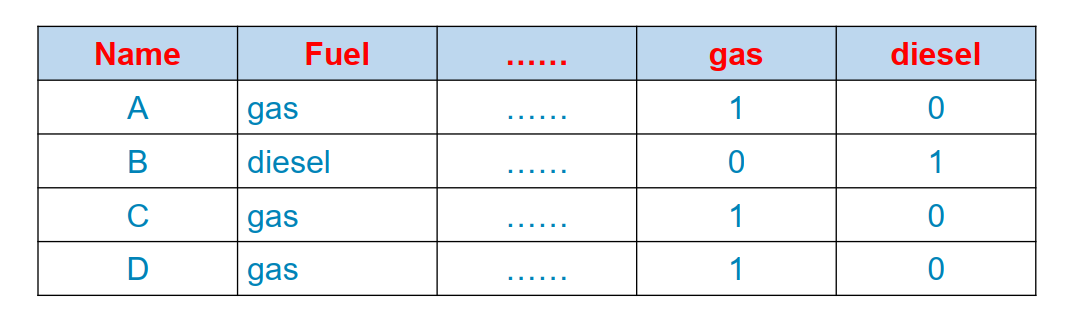

tách 2 giá trị phân loại gas và diesel thành 2 cột riêng biệt (series thêm)




### Cú pháp:
        pd.get_dummies(
            data,
            prefix=None,
            prefix_sep='_’,
            dummy_na=False,
            columns=None,
            sparse=False,
            drop_first=False,
            dtype=None,
        ) -> 'DataFrame’

In [34]:
df1=pd.get_dummies(df['fuel-type'])
# ban đầu giá trị là true false

### Hàm `concat()`

#### Dùng để nối các DataFrame lại với nhau

Ví dụ: nối `df` ban đầu với `df2` mới tạo (sau khi tách/phân loại dữ liệu).

#### 1. `axis=1` → nối theo cột

Ví dụ, nối 2 DataFrame:

**df:**

| price |
|---:|
| 10000 |
| 20000 |
| 30000 |

**df2:**

| gas |
|---:|
| 1 |
| 0 |
| 1 |

Sau khi nối:

| price | gas |
|---:|---:|
| 10000 | 1 |
| 20000 | 0 |
| 30000 | 1 |

#### 2.`axis=0` → nối theo dòng

| price |
| ----: |
| 10000 |
| 20000 |

| price |
| ----: |
| 30000 |
| 40000 |

#### Sau khi nối:

| price |
| ----: |
| 10000 |
| 20000 |
| 30000 |
| 40000 |


In [38]:
df3=pd.concat([df,df1], axis=1)
df3
#

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,price_bin,diesel,gas
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,3.40,10.0,102,5500,24,30,13950.0,T,False,True
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,3.40,8.0,115,5500,18,22,17450.0,V,False,True
6,1,158,audi,gas,std,four,sedan,fwd,front,105.8,...,3.40,8.5,110,5500,19,25,17710.0,V,False,True
8,1,158,audi,gas,turbo,four,sedan,fwd,front,105.8,...,3.40,8.3,140,5500,17,20,23875.0,V,False,True
10,2,192,bmw,gas,std,two,sedan,rwd,front,101.2,...,2.80,8.8,101,5800,23,29,16430.0,V,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,3.15,9.5,114,5400,23,28,16845.0,V,False,True
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,3.15,8.7,160,5300,19,25,19045.0,V,False,True
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,2.87,8.8,134,5500,18,23,21485.0,V,False,True
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,3.40,23.0,106,4800,26,27,22470.0,V,True,False


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,price_bin
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,T
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,V
6,1,158,audi,gas,std,four,sedan,fwd,front,105.8,...,mpfi,3.19,3.40,8.5,110,5500,19,25,17710.0,V
8,1,158,audi,gas,turbo,four,sedan,fwd,front,105.8,...,mpfi,3.13,3.40,8.3,140,5500,17,20,23875.0,V
10,2,192,bmw,gas,std,two,sedan,rwd,front,101.2,...,mpfi,3.50,2.80,8.8,101,5800,23,29,16430.0,V
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0,V
201,-1,95,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0,V
202,-1,95,volvo,gas,std,four,sedan,rwd,front,109.1,...,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0,V
203,-1,95,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,idi,3.01,3.40,23.0,106,4800,26,27,22470.0,V


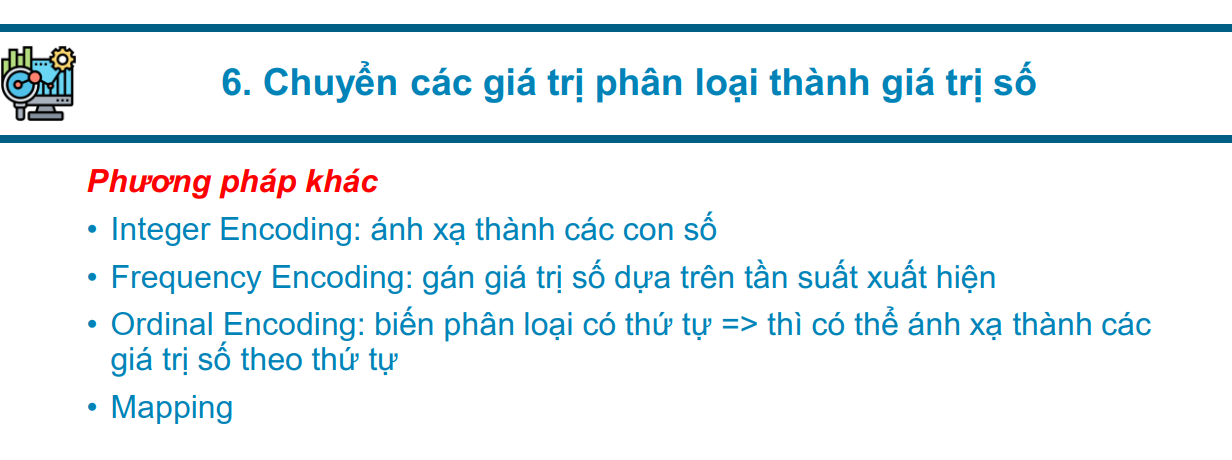

nên xài onehot trước cho ngườui cơ